## Extension 2 - Probabilistic Initial Adoption

**Paper:** Evaluating Stochastic Seeding Strategies in Networks (Chin et al., 2022, Management Science)

**Data:** Cai et al. (2015) village network

Our second extension is to examine how one-hop and random targeting perform when selected seeds do not always adopt. In the paper’s simulations, all selected seeds are assumed to adopt the behavior initially, but in the real world, receiving an intervention does not guarantee adoption. Thus, in our extension, we want to assign each selected seed an initial adoption probability and see how this affects the results. We plan to try three scenarios: 1) the same probability for all seeds, 2) lower probabilities for seeds with higher in-degree, and 3) higher probabilities for seeds with higher in-degree. Using the Cai network data and simulation framework (Figures 2-4), we will set initial adoption probabilities for selected seeds based on the three scenarios and compare final adoption rates under one-hop and random targeting. We also plan to compare the estimators' RMSE and 90% confidence interval coverage.

**Analysis Plan**

(1) compare three representative degree–adoption scenarios, including estimator RMSE and 90% CI coverage

(2) examine targeting effect reversal and look for a possible crossover $\gamma^*$

In [12]:
from pathlib import Path
import itertools
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from scipy.special import expit
from scipy.optimize import brentq
from scipy.stats import norm

### 1. Data

In [ ]:
data_path = Path("../data/0422allinforawnet.dta")
reps = 5000
seed = 6165
p_base = 0.7
alphas = (-3, -2, -1, 0)
betas = (0, 2, 4, 6, 8, 10)
ns = (50, 150)
analysis1_gamma = {"negative": -0.5, "equal": 0.0, "positive": 0.5}
analysis2_gamma = np.linspace(-1.0, 1.0, 21)

In [14]:
colors = {"dm": "#E69F00", "hajek": "#009E73", "ht": "#56B4E9"}
labels = {"dm": "difference-in-means", "hajek": "Hajek", "ht": "Horvitz-Thompson"}
markers = {"dm": "s", "hajek": "^", "ht": "o"}

### 2. Network preprocessing and one-hop seed probabilities

In [ ]:
# Network preprocessing and seed-selection probabilities

def load_villages(path):
    df = pd.read_stata(path, convert_categoricals=False)
    df['address'] = df['address'].astype('string')
    df['network_address'] = df['network_address'].astype('string')

    addresses = pd.unique(df['address'].dropna())
    villages = []
    for address in addresses:

        # Skip if address is empty
        if address == '':
            continue

        # Keep valid within-village edges
        sub = df.loc[(df['address'] == address) &
                     (df['network_address'] == address) &
                     df['network_id'].notna() &
                     (df['id'] != 99) &
                     (df['network_id'] != 99),
                     ['id', 'network_id']]

        # Filter num edge <= 25
        if len(sub) <= 25:
            continue

        # Create a directed network
        graph = nx.DiGraph()
        graph.add_edges_from(sub.itertuples(index=False, name=None))

        nodes = list(graph.nodes())
        n = len(nodes)

        # Skip if num nodes < 2 (need to select at least 2 seeds)
        if n < 2:
            continue

        # Create adjacency matrix
        adjacency = nx.to_numpy_array(graph, nodelist=nodes, dtype=float)

        # One-hop nomination probabilities
        row_degrees = adjacency.sum(axis=1)   # out-degree
        valid = row_degrees > 0
        q = (adjacency[valid] / row_degrees[valid, None]).sum(axis=0) / valid.sum()

        # All possible pairs of two seeds
        pairs = np.array(list(itertools.combinations(range(n), 2)), dtype=np.int32)

        # Random targeting seed set probabilities
        p_rand = np.full(len(pairs), 1.0 / len(pairs))

        # One-hop targeting seed set probabilities
        weights = q[pairs[:, 0]] * q[pairs[:, 1]]
        p_nom = weights / weights.sum()

        # Row-normalized adjacency matrix for adoption diffusion
        norm_adj = np.divide(adjacency,
                             row_degrees[:, None],
                             out=np.zeros_like(adjacency),
                             where=row_degrees[:, None] > 0)

        villages.append({'n': n,
                         'pairs': pairs,
                         'p_rand': p_rand,
                         'p_nom': p_nom,
                         'norm_adj': norm_adj,
                         'in_degrees': adjacency.sum(axis=0)})

    return villages

### 3. Probabilistic initial adoption and diffusion

For village $i$ and node $v$:

$$
p_{iv}(\gamma)=\operatorname{logistic}\left(a_i(\gamma)+\gamma d_{iv}^{\mathrm{in}}\right)
$$

The intercept is calibrated for each village and each $\gamma$ so that

$$
\frac{1}{n_i}\sum_v p_{iv}(\gamma)=p_0
$$

At $\gamma=0$, each node has probability exactly $p_0$; negative/positive values create decreasing/increasing relationships with in-degree. Each selected seed draws its initial adoption independently. Nonadopting seeds can still adopt during later diffusion rounds, just like other nodes.

In [ ]:
# Degree-based initial adoption probabilities

def initial_adoption_probs(v, gamma, p_base=0.7):
    degree = v['in_degrees']
    x = gamma * (degree - degree.mean())

    # Calibrate the mean initial adoption probability to p_base
    bound = np.max(np.abs(x)) + 40
    a = brentq(lambda a: expit(a + x).mean() - p_base,
               -bound, bound)

    return expit(a + x)

In [ ]:
# Probabilistic initial adoption and diffusion

def outcome(v, seeds, intercept, spillover, rng, initial_probs):
    # Initialize seed adoption probabilistically
    y = np.zeros(v['n'], dtype=bool)
    y[seeds] = rng.random(len(seeds)) < initial_probs[seeds]

    # Simulate three diffusion time steps
    for _ in range(3):
        avg_neighbors = v['norm_adj'] @ y.astype(float)
        latent = intercept + spillover * avg_neighbors + rng.standard_normal(v['n'])
        y |= latent > 0

    return float(y.mean())

### 4. Estimators and variance estimates

In [ ]:
# Treatment-effect estimators and variance estimates

def estimate(y, w, pr, pn, rho=0.5):
    n = len(y)

    # Seed-selection weights
    design = rho * pn + (1 - rho) * pr
    weight_a = pn / design
    weight_b = pr / design

    # Difference-in-means estimator
    y_a = y[w == 1]
    y_b = y[w == 0]
    dm = (y_a.mean() - y_b.mean()) if len(y_a) > 0 and len(y_b) > 0 else np.nan

    # Horvitz-Thompson estimator
    score = (weight_a - weight_b) * y
    ht = np.mean(score)

    # Hajek estimator
    mu_a = np.sum(weight_a * y) / np.sum(weight_a)
    mu_b = np.sum(weight_b * y) / np.sum(weight_b)
    hajek = mu_a - mu_b

    # Variance estimates
    dmvar = (np.var(y_a, ddof=1) / len(y_a) + np.var(y_b, ddof=1) / len(y_b)) if len(y_a) > 1 and len(y_b) > 1 else np.nan
    htvar = np.mean((score - ht) ** 2) / n
    hscore = mu_a * weight_a - mu_b * weight_b - score
    hvar = np.mean(hscore ** 2) / n

    return {'dm': dm,
            'ht': ht,
            'hajek': hajek,
            'dm_var_est': dmvar,
            'ht_var_est': htvar,
            'hajek_var_est': hvar}

### 5. One Monte Carlo replication

In [ ]:
# One Monte Carlo replication

def one_rep(villages, n_villages, intercept, spillover, gamma, rng, probabilities):
    # Sample villages without replacement
    indices = rng.choice(len(villages), size=n_villages, replace=False)

    y = np.zeros(n_villages)
    yn = np.zeros(n_villages)
    yr = np.zeros(n_villages)
    pr = np.zeros(n_villages)
    pn = np.zeros(n_villages)

    # Assign targeting strategies
    w = rng.binomial(1, 0.5, size=n_villages)

    for j, idx in enumerate(indices):
        v = villages[idx]

        # Select seed pairs under both strategies
        nom_idx = rng.choice(len(v['pairs']), p=v['p_nom'])
        rand_idx = rng.choice(len(v['pairs']), p=v['p_rand'])

        selected_idx = nom_idx if w[j] else rand_idx

        # Probabilities of the observed seed pair
        pr[j] = v['p_rand'][selected_idx]
        pn[j] = v['p_nom'][selected_idx]

        # Simulate adoption outcomes under both strategies
        yn[j] = outcome(v, v['pairs'][nom_idx], intercept, spillover,
                        rng, probabilities[idx])
        yr[j] = outcome(v, v['pairs'][rand_idx], intercept, spillover,
                        rng, probabilities[idx])

        # Observed outcome under the assigned strategy
        y[j] = yn[j] if w[j] else yr[j]

    # Estimate treatment effects and variances
    result = estimate(y, w, pr, pn)

    result.update({'tau_rep': float((yn - yr).mean()),
                   'adoption_onehop': float(yn.mean()),
                   'adoption_random': float(yr.mean()),
                   'n_villages': n_villages,
                   'intercept': intercept,
                   'b_spill': spillover,
                   'gamma': gamma})

    return result


# Precompute initial adoption probabilities for each village
def build_probabilities(villages, gamma, p_base):
    return [initial_adoption_probs(v, gamma, p_base) for v in villages]

### 6. Summaries and inferential diagnostics

In [ ]:
# Summarize estimator performance (Analysis 1)

def summarize_estimators(raw):
    rows = []
    group_cols = ['scenario', 'gamma', 'n_villages', 'intercept', 'b_spill']
    z = norm.ppf(0.95)

    for keys, group in raw.groupby(group_cols, sort=True):
        params = dict(zip(group_cols, keys))
        tau = group['tau_rep'].to_numpy()
        tau_mean = tau.mean()

        for name in ('dm', 'ht', 'hajek'):
            est = group[name].to_numpy()
            var = group[f'{name}_var_est'].to_numpy()
            rmse = np.sqrt(np.nanmean((est - tau) ** 2))   # RMSE
            valid = np.isfinite(est) & np.isfinite(var) & (var >= 0)
            coverage = np.full(len(est), np.nan)
            coverage[valid] = (np.abs(est[valid] - tau_mean) <= z * np.sqrt(var[valid]))   # 90% confidence interval coverage

            rows.append({**params,
                         'estimator': name,
                         'tau_mean': tau_mean,
                         'rmse': rmse,
                         'coverage': np.nanmean(coverage),
                         'mean_estimate': np.nanmean(est)})

    return pd.DataFrame(rows)

In [ ]:
# Summarize adoption rates (Analysis 1 and 2)

def adoption_summary(raw, group_cols):
    result = (raw.groupby(group_cols, as_index=False)[['adoption_onehop', 'adoption_random']].mean())
    result['difference'] = result['adoption_onehop'] - result['adoption_random']
    return result

### 8. Cai et al. network data  

In [ ]:
# Load village networks
villages = load_villages(data_path)
print(f"Number of villages: {len(villages)}")

Villages: 150; mean nodes: 42.69; min: 17; max: 95
Seed-set probability sums and adoption-probability calibration: OK


### 8. Analysis 1 — Three Adoption Scenarios

In [ ]:
# check
for scenario, gamma in analysis1_gamma.items():
    probs = build_probabilities(villages, gamma, p_base)
    print(f"{scenario}: {np.mean(probs[0]):.6f}")

negative: 0.700000
equal: 0.700000
positive: 0.700000


In [ ]:
scenario_rng = np.random.default_rng(seed)
scenario_results = []
total_conditions = (len(analysis1_gamma) * len(ns) * len(alphas) * len(betas))
completed = 0

for scenario, gamma in analysis1_gamma.items():
    probs = build_probabilities(villages, gamma, p_base)
    for N in ns:
        for alpha in alphas:
            for beta in betas:
                for rep in range(reps):
                    result = one_rep(villages, N, alpha, beta, gamma,
                                     scenario_rng, probs)
                    result["scenario"] = scenario
                    result["rep"] = rep + 1
                    scenario_results.append(result)
                completed += 1
                print(f"Scenario={scenario}, N={N}, alpha={alpha}, beta={beta} | "
                      f"Progress: {completed / total_conditions:.1%}", flush=True)

scenario_raw = pd.DataFrame(scenario_results)
scenario_raw.to_csv("extension2_scenarios_raw.csv", index=False)
scenario_summary = summarize_estimators(scenario_raw)
scenario_adoption = adoption_summary(scenario_raw, ["scenario", "gamma", "n_villages", "intercept", "b_spill"])
scenario_summary.to_csv("extension2_scenarios_estimators.csv", index=False)
scenario_adoption.to_csv("extension2_scenarios_adoption.csv", index=False)
print(f"Simulation rows: {len(scenario_raw):,}")
display(scenario_adoption.head())
display(scenario_summary.head())

Scenario=negative, N=50, alpha=-3, beta=0 | Progress: 0.7%
Scenario=negative, N=50, alpha=-3, beta=2 | Progress: 1.4%
Scenario=negative, N=50, alpha=-3, beta=4 | Progress: 2.1%
Scenario=negative, N=50, alpha=-3, beta=6 | Progress: 2.8%
Scenario=negative, N=50, alpha=-3, beta=8 | Progress: 3.5%
Scenario=negative, N=50, alpha=-3, beta=10 | Progress: 4.2%
Scenario=negative, N=50, alpha=-2, beta=0 | Progress: 4.9%
Scenario=negative, N=50, alpha=-2, beta=2 | Progress: 5.6%
Scenario=negative, N=50, alpha=-2, beta=4 | Progress: 6.2%
Scenario=negative, N=50, alpha=-2, beta=6 | Progress: 6.9%
Scenario=negative, N=50, alpha=-2, beta=8 | Progress: 7.6%
Scenario=negative, N=50, alpha=-2, beta=10 | Progress: 8.3%
Scenario=negative, N=50, alpha=-1, beta=0 | Progress: 9.0%
Scenario=negative, N=50, alpha=-1, beta=2 | Progress: 9.7%
Scenario=negative, N=50, alpha=-1, beta=4 | Progress: 10.4%
Scenario=negative, N=50, alpha=-1, beta=6 | Progress: 11.1%
Scenario=negative, N=50, alpha=-1, beta=8 | Progress

,scenario,gamma,n_villages,intercept,b_spill,adoption_onehop,adoption_random,tau_rep,difference
0,equal,0.0,50,-3,0,0.041689,0.041757,-0.000068,-0.000068
1,equal,0.0,50,-3,2,0.044617,0.043313,0.001304,0.001304
2,equal,0.0,50,-3,4,0.055467,0.049224,0.006244,0.006244
3,equal,0.0,50,-3,6,0.085482,0.066313,0.019170,0.019170
4,equal,0.0,50,-3,8,0.144933,0.103414,0.041519,0.041519


,scenario,gamma,n_villages,intercept,b_spill,estimator,tau_mean,rmse,coverage,mean_estimate
0,equal,0.0,50,-3,0,dm,-0.000068,0.006212,0.8940,-0.000040
1,equal,0.0,50,-3,0,ht,-0.000068,0.007552,0.8866,-0.000022
2,equal,0.0,50,-3,0,hajek,-0.000068,0.004802,0.8864,-0.000049
3,equal,0.0,50,-3,2,dm,0.001304,0.006803,0.8962,0.001204
4,equal,0.0,50,-3,2,ht,0.001304,0.008074,0.8852,0.001214


### 9. Analysis 1 plots

The first plot compares final adoption rates under both policies in the three scenarios for a selected $N$ and $\alpha$. The second shows RMSE and 90% coverage of each estimator by scenario (at a selected $\beta$).

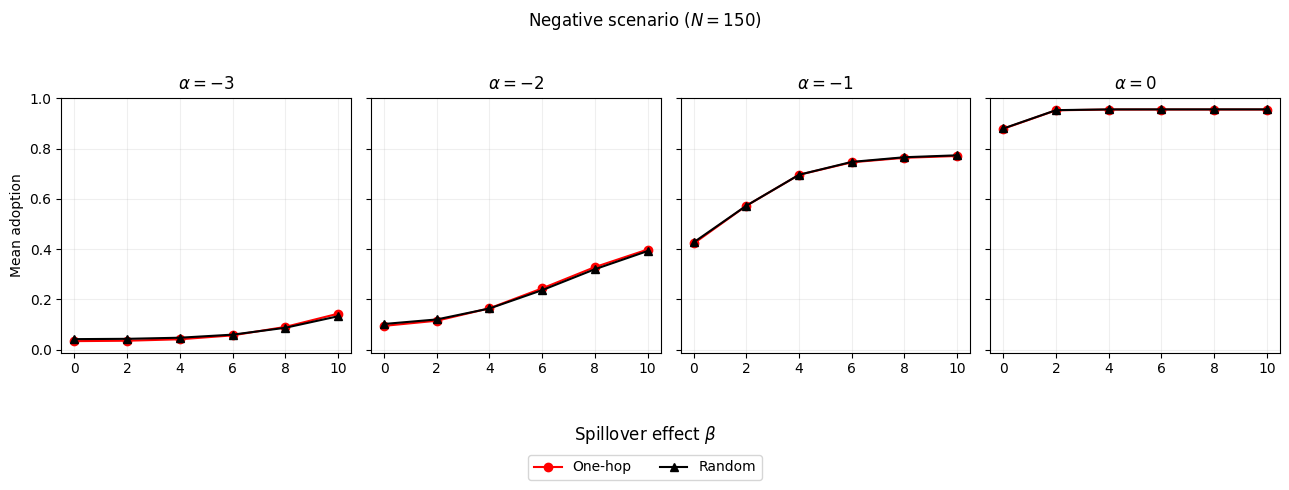

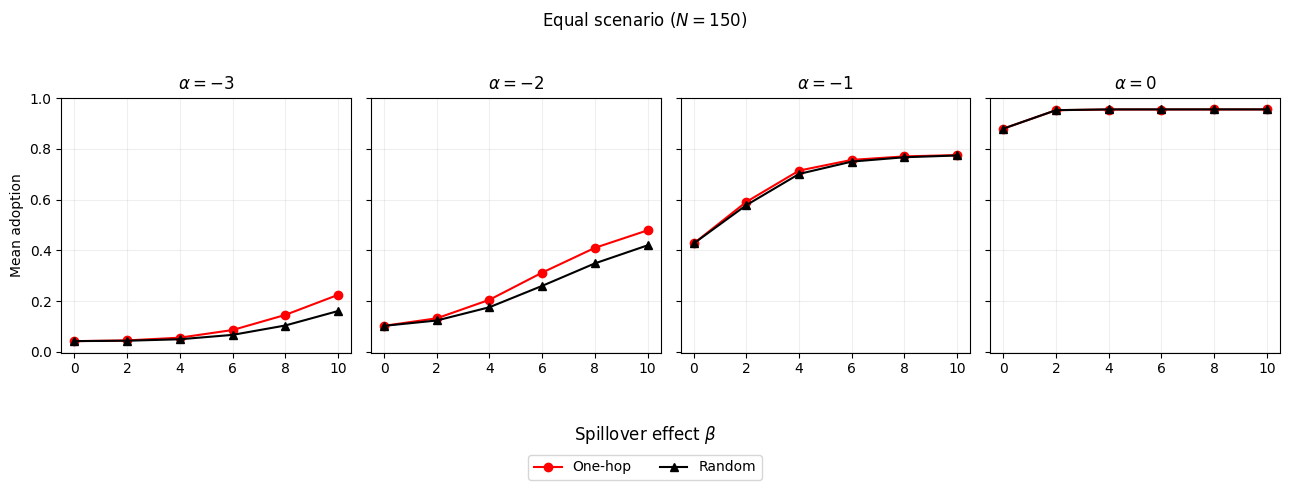

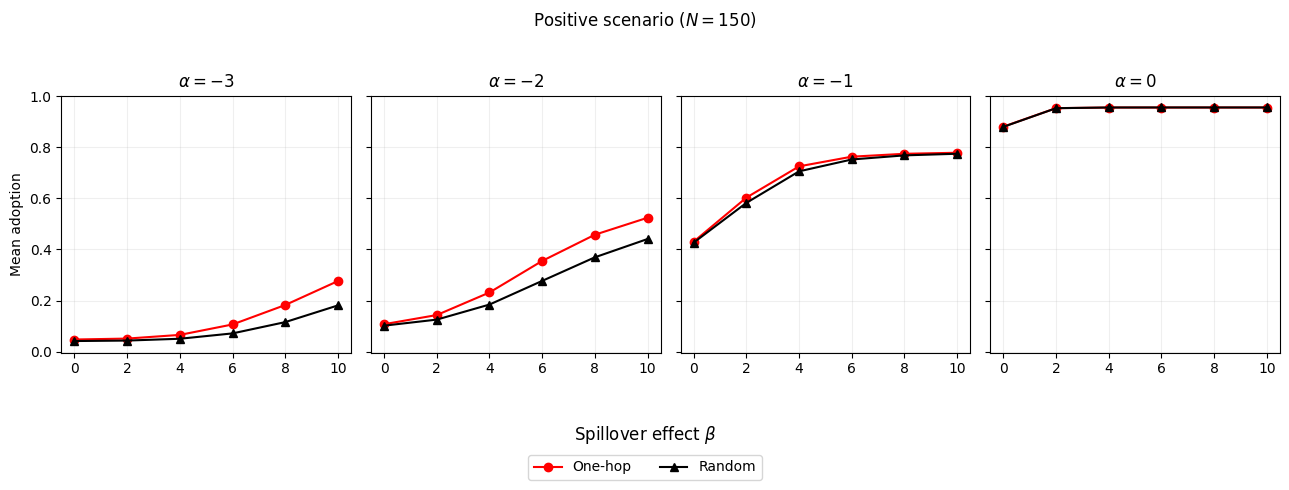

In [ ]:
def plot_adoption_by_scenario(data, scenario, N=150):
    d = data[(data["scenario"] == scenario) & (data["n_villages"] == N)]
    fig, axes = plt.subplots(1, 4, figsize=(13, 4.5), sharey=True)

    for ax, alpha in zip(axes, alphas):
        sub = d[d["intercept"] == alpha].sort_values("b_spill")
        ax.plot(sub["b_spill"], sub["adoption_onehop"], color="red", marker="o", label="One-hop")
        ax.plot(sub["b_spill"], sub["adoption_random"], color="black", marker="^", label="Random")
        ax.set_title(rf"$\alpha={alpha}$")
        ax.set_xticks(betas)
        ax.grid(alpha=0.2)

    axes[0].set_ylabel("Mean adoption")
    fig.supxlabel(r"Spillover effect $\beta$")
    fig.suptitle(f"{scenario.capitalize()} scenario ($N={N}$)")
    fig.legend(["One-hop", "Random"],
               loc="lower center", ncol=2,
               bbox_to_anchor=(0.5, -0.08))
    plt.tight_layout(rect=[0, 0.05, 1, 0.95])
    plt.show()

for scenario in analysis1_gamma:
    plot_adoption_by_scenario(scenario_adoption, scenario, N=150)

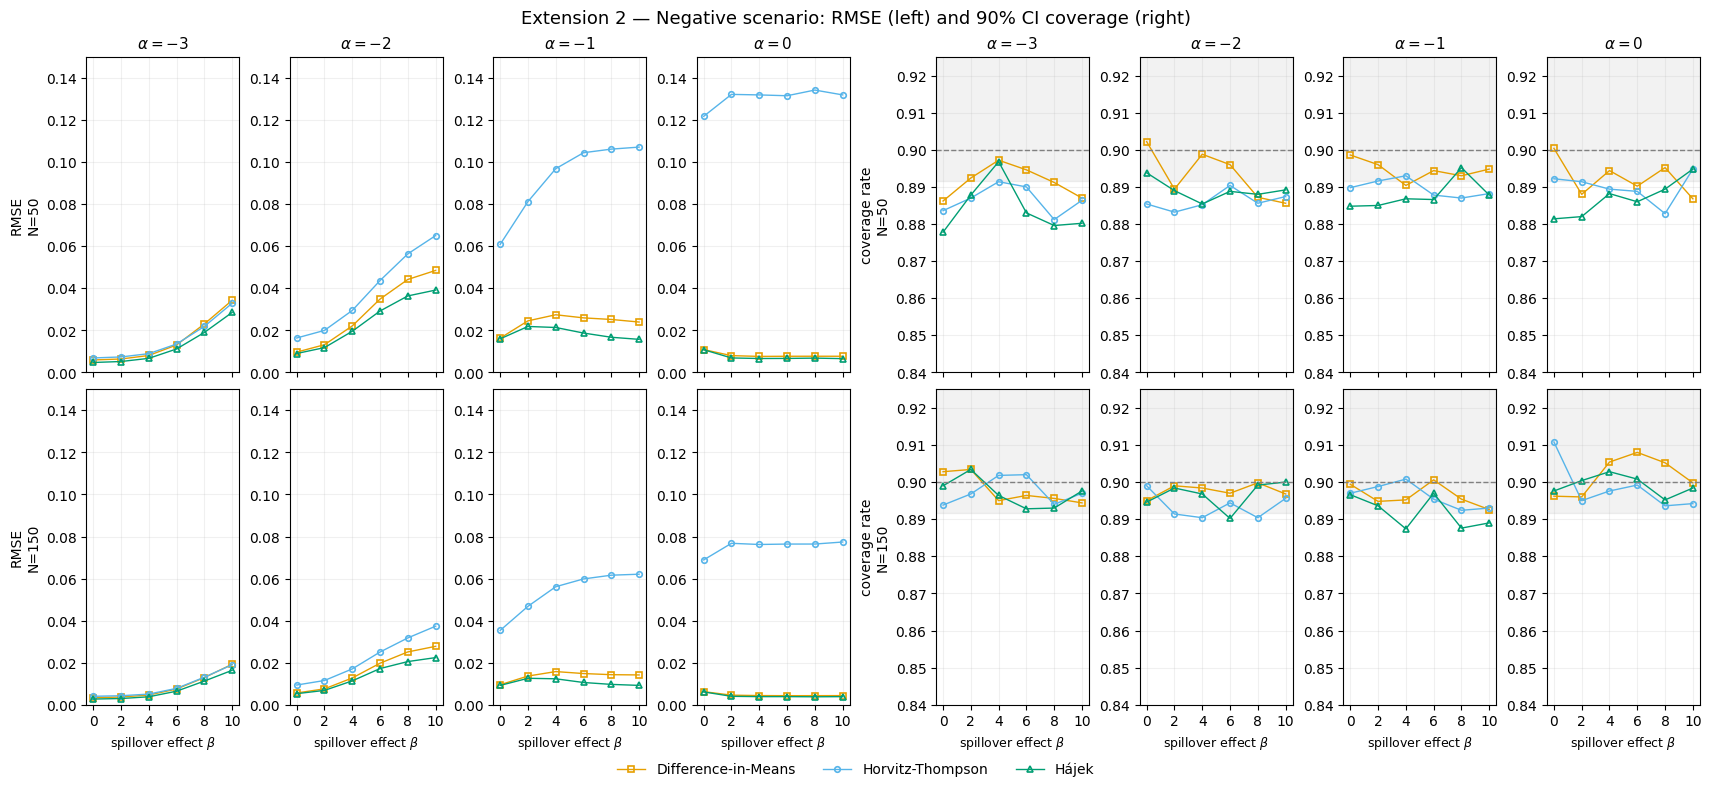

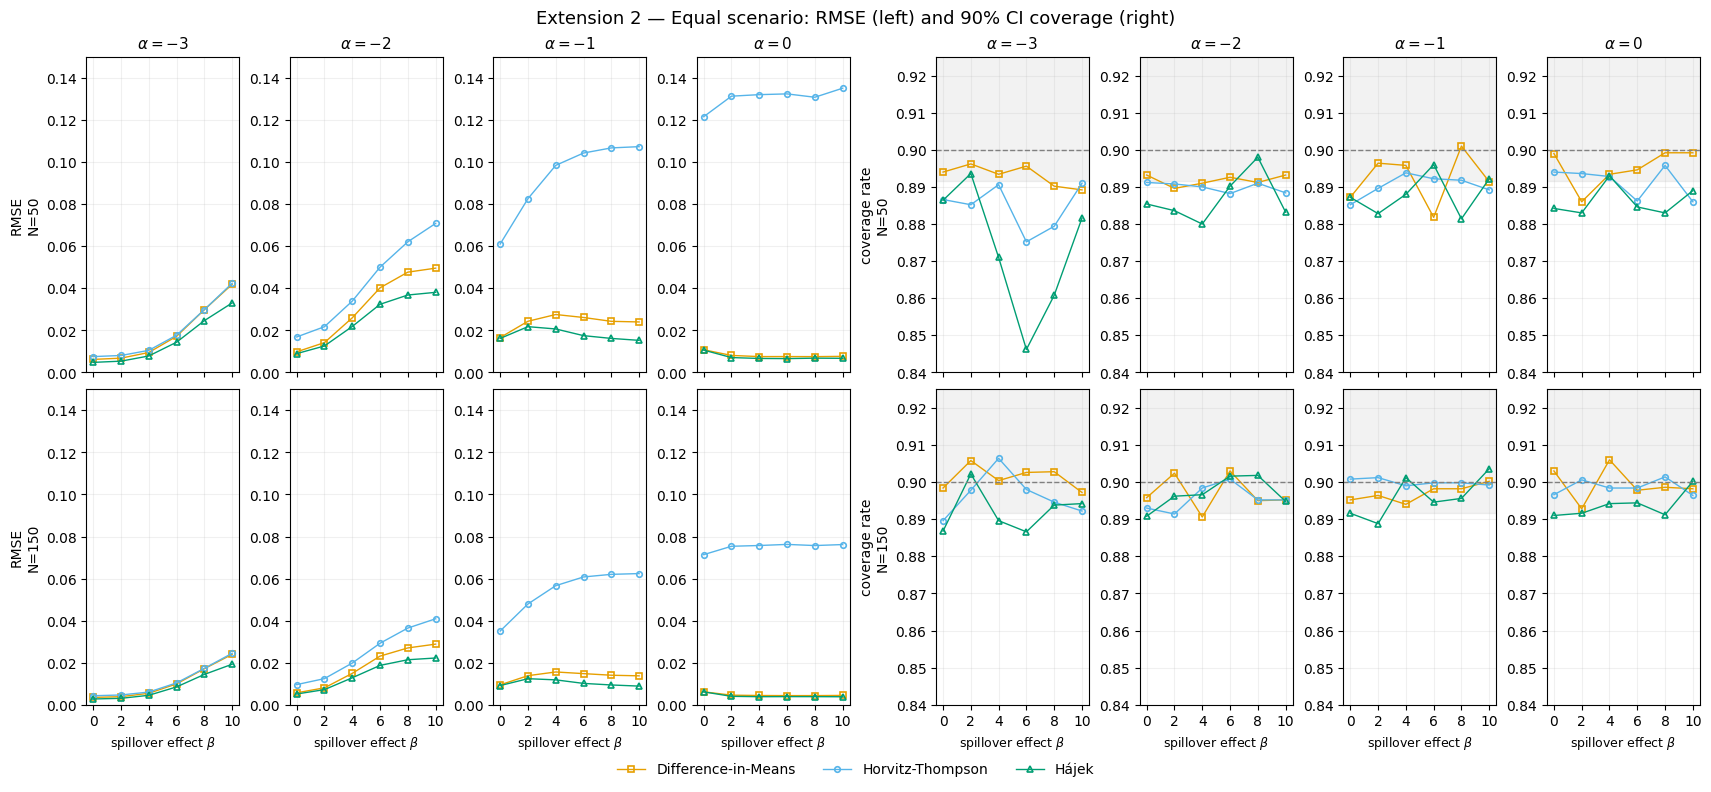

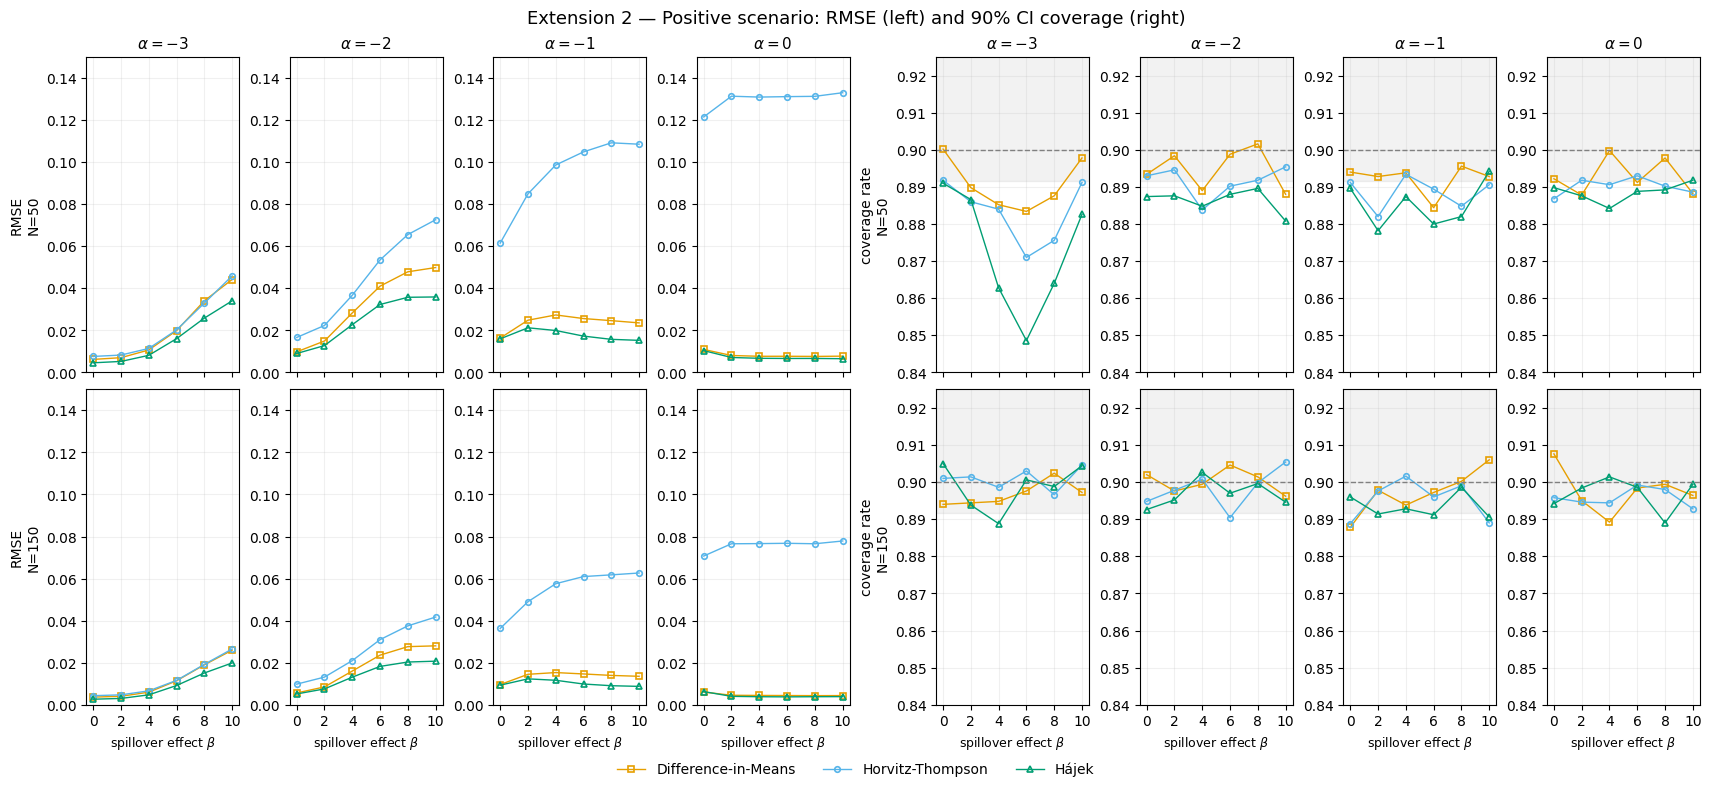

In [ ]:
# RMSE & Coverage

def plot_figure3(summary, reps, scenario):
    colors = {"dm": "#E69F00", "ht": "#56B4E9", "hajek": "#009E73"}
    markers = {"dm": "s", "ht": "o", "hajek": "^"}
    labels = {"dm": "Difference-in-Means", "hajek": "Hájek", "ht": "Horvitz-Thompson"}

    alpha_vals = [-3, -2, -1, 0]
    nvals = [50, 150]

    fig, axes = plt.subplots(2, 8, figsize=(17, 7.5), sharex=True, layout="constrained")

    for ri, N in enumerate(nvals):
        for ci, a in enumerate(alpha_vals):
            for side in (0, 1):
                ax = axes[ri, ci + side * 4]
                d = summary[(summary.n_villages == N) & (summary.intercept == a)]

                for key in ("dm", "ht", "hajek"):
                    q = d[d.estimator == key].sort_values("b_spill")

                    ax.plot(
                        q.b_spill,
                        q.rmse if side == 0 else q.coverage,
                        color=colors[key],
                        marker=markers[key],
                        markerfacecolor="none",
                        markeredgewidth=1.2,
                        markersize=4,
                        linewidth=1,
                        label=labels[key]
                    )

                ax.set_xticks([0, 2, 4, 6, 8, 10])
                ax.grid(alpha=.18)

                if ri == 0:
                    ax.set_title(rf"$\alpha={a}$", fontsize=11)

                if ri == 1:
                    ax.set_xlabel(r"spillover effect $\beta$", fontsize=9)

                if ci == 0 and side == 0:
                    ax.set_ylabel(f"RMSE\nN={N}")

                if ci == 0 and side == 1:
                    ax.set_ylabel(f"coverage rate\nN={N}")

                if side == 0:
                    ax.set_ylim(0, .15)
                else:
                    ax.axhline(.90, color="gray", linestyle="--", linewidth=1)
                    band_bottom = .90 - 1.96 * np.sqrt(.9 * .1 / reps)
                    ax.axhspan(band_bottom, 1, color="gray", alpha=.10)
                    ax.set_ylim(.84, .925)

    handles, legend_labels = axes[0, 0].get_legend_handles_labels()

    fig.legend(handles, legend_labels, ncol=3, loc="outside lower center", bbox_to_anchor=(.5, -.045), frameon=False)
    fig.suptitle(f"Extension 2 — {scenario.capitalize()} scenario: "
                 "RMSE (left) and 90% CI coverage (right)", fontsize=13)
    plt.show()

for scenario in analysis1_gamma:
    data = scenario_summary[scenario_summary["scenario"] == scenario]
    plot_figure3(data, reps, scenario)

### 10. Analysis 2 — Targeting Effect Reversal

In [ ]:
# Analysis 2-only selection from the shared grid
sensitivity_n = 150
sensitivity_alphas = (-3, -2)

sensitivity_rng = np.random.default_rng(seed + 1)
sensitivity_rows = []

total_conditions = (len(sensitivity_alphas) * len(analysis2_gamma) * len(betas))
completed = 0

for alpha in sensitivity_alphas:
    for gamma in analysis2_gamma:
        probs = build_probabilities(villages, gamma, p_base)

        for beta in betas:
            for rep in range(reps):
                result = one_rep(villages, sensitivity_n, alpha, beta,
                                 gamma, sensitivity_rng, probs)

                sensitivity_rows.append({
                    "alpha": alpha,
                    "gamma": float(gamma),
                    "beta": beta,
                    "rep": rep + 1,
                    "adoption_onehop": result["adoption_onehop"],
                    "adoption_random": result["adoption_random"],
                    "tau_rep": result["tau_rep"]
                })

            completed += 1
            print(f"alpha={alpha}, γ={gamma:+.2f}, beta={beta} | "
                  f"Progress: {completed / total_conditions:.1%}", flush=True)

sensitivity_raw = pd.DataFrame(sensitivity_rows)
sensitivity_raw.to_csv("extension2_sensitivity_raw.csv", index=False)

sensitivity_summary = adoption_summary(sensitivity_raw, ["alpha", "gamma", "beta"])
sensitivity_summary.to_csv("extension2_sensitivity_summary.csv", index=False)

print(f"Simulation rows: {len(sensitivity_raw):,}")
display(sensitivity_summary.head())

alpha=-3, γ=-1.00, beta=0 | Progress: 0.4%
alpha=-3, γ=-1.00, beta=2 | Progress: 0.8%
alpha=-3, γ=-1.00, beta=4 | Progress: 1.2%
alpha=-3, γ=-1.00, beta=6 | Progress: 1.6%
alpha=-3, γ=-1.00, beta=8 | Progress: 2.0%
alpha=-3, γ=-1.00, beta=10 | Progress: 2.4%
alpha=-3, γ=-0.90, beta=0 | Progress: 2.8%
alpha=-3, γ=-0.90, beta=2 | Progress: 3.2%
alpha=-3, γ=-0.90, beta=4 | Progress: 3.6%
alpha=-3, γ=-0.90, beta=6 | Progress: 4.0%
alpha=-3, γ=-0.90, beta=8 | Progress: 4.4%
alpha=-3, γ=-0.90, beta=10 | Progress: 4.8%
alpha=-3, γ=-0.80, beta=0 | Progress: 5.2%
alpha=-3, γ=-0.80, beta=2 | Progress: 5.6%
alpha=-3, γ=-0.80, beta=4 | Progress: 6.0%
alpha=-3, γ=-0.80, beta=6 | Progress: 6.3%
alpha=-3, γ=-0.80, beta=8 | Progress: 6.7%
alpha=-3, γ=-0.80, beta=10 | Progress: 7.1%
alpha=-3, γ=-0.70, beta=0 | Progress: 7.5%
alpha=-3, γ=-0.70, beta=2 | Progress: 7.9%
alpha=-3, γ=-0.70, beta=4 | Progress: 8.3%
alpha=-3, γ=-0.70, beta=6 | Progress: 8.7%
alpha=-3, γ=-0.70, beta=8 | Progress: 9.1%
alpha=-3

,alpha,gamma,beta,adoption_onehop,adoption_random,tau_rep,difference
0,-3,-1.0,0,0.030229,0.041747,-0.011518,-0.011518
1,-3,-1.0,2,0.031468,0.042805,-0.011337,-0.011337
2,-3,-1.0,4,0.035500,0.046562,-0.011062,-0.011062
3,-3,-1.0,6,0.046360,0.056765,-0.010405,-0.010405
4,-3,-1.0,8,0.070643,0.080211,-0.009567,-0.009567


### 11. Targeting effect reversal plot and crossover points

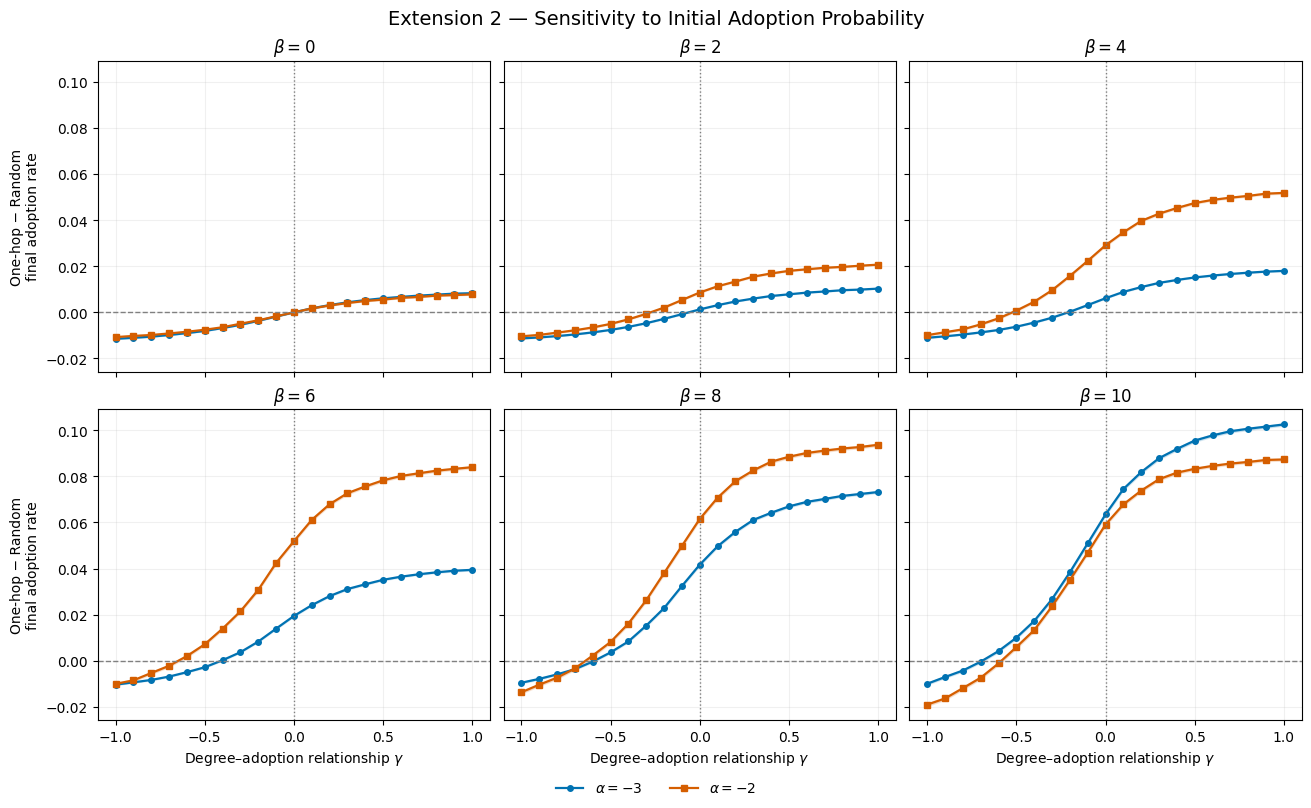

In [ ]:
# Analysis 2 plot
plot_summary = (sensitivity_raw
                .groupby(["alpha", "beta", "gamma"])["tau_rep"]
                .agg(["mean", "std", "count"])
                .reset_index())
plot_summary["se"] = (plot_summary["std"] / np.sqrt(plot_summary["count"]))
plot_summary["ci_lower"] = (plot_summary["mean"] - 1.96 * plot_summary["se"])
plot_summary["ci_upper"] = (plot_summary["mean"] + 1.96 * plot_summary["se"])

def plot_sensitivity(plot_summary):
    colors = {-3: "#0072B2", -2: "#D55E00"}
    markers = {-3: "o", -2: "s"}
    beta_vals = sorted(plot_summary["beta"].unique())
    fig, axes = plt.subplots(2, 3, figsize=(13, 8), sharex=True, sharey=True, layout="constrained")

    for ax, beta in zip(axes.flat, beta_vals):
        d = plot_summary[plot_summary["beta"] == beta]

        for alpha in (-3, -2):
            q = d[d["alpha"] == alpha].sort_values("gamma")
            ax.plot(q["gamma"], q["mean"], color=colors[alpha],
                    marker=markers[alpha], markersize=4, linewidth=1.6,
                    label=rf"$\alpha={alpha}$")
            ax.fill_between(q["gamma"], q["ci_lower"], q["ci_upper"],
                            color=colors[alpha], alpha=0.15)

        ax.axhline(0, color="gray", linestyle="--", linewidth=1)
        ax.axvline(0, color="gray", linestyle=":", linewidth=1)
        ax.set_title(rf"$\beta={beta}$", fontsize=12)
        ax.set_xticks([-1, -0.5, 0, 0.5, 1])
        ax.grid(alpha=0.18)

    for ax in axes[-1]:
        ax.set_xlabel(r"Degree–adoption relationship $\gamma$")

    for ax in axes[:, 0]:
        ax.set_ylabel("One-hop − Random\nfinal adoption rate")

    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, ncol=2, loc="outside lower center", frameon=False)
    fig.suptitle("Extension 2 — Sensitivity to Initial Adoption Probability", fontsize=14)
    plt.show()

plot_sensitivity(plot_summary)